# HW1: Frame-Level Speech Recognition

In this homework, you will be working with log-mel spectrogram data consisting of 32 features at each time step/frame. Your model should be able to recognize the phoneme occured in that frame.

# Schedule:
- Checkpoint Submission (DUE 4 September 2026 @ 11:59PM ET)
- Final Submission (DUE 18 September 2026 @ 11:59PM ET | Slack Deadline is 25 September 2026 @ 11:59PM ET)
- Code Submission (DUE 20 September 2026 @ 11:59PM ET OR Day-of Slack submission)


## Requirement Acknowledgement
Setting the below flag to True indicates full understanding and acceptance of the following:
1. Slack days may ONLY be used on P2 FINAL (not checkpoint) submission. I.e. you may use slack days to submit final P2 kaggle scores (such as this one) later on the **SLACK KAGGLE COMPETITION** at the expense of your Slack days.
2. The final Gradescope **code submission is due 48 hours after** the conclusion of the Kaggle Deadline (or, the same day as your final kaggle submission).
3. We will require your kaggle username here, and then we will pull your official PRIVATE kaggle leaderboard score. This submission may result in slight variance in scores/code, but we will check for acceptable discrepancies. Any discrepancies related to modifying the submission code (at the bottom of the notebook) will result in an AIV.
4. You are NOT allowed to use any code that will pre-load models (such as those from Hugging Face, etc.).
   You MAY use models described by papers or articles, but you MUST implement them yourself through fundamental PyTorch operations (i.e. Linear, Conv2d, etc.).
5. You are NOT allowed to use any external data/datasets at ANY point of this assignment.
6. You may work with teammates to run ablations/experiments, BUT you must submit your OWN code and your OWN results.
7. Failure to comply with the prior rules will be considered an Academic Integrity Violation (AIV).
8. Late submissions MUST be submitted through the Slack Kaggle (see writeup for details). Any submissions made to the regular Kaggle after the original deadline will NOT be considered, no matter how many slack days remain for the student.

In [1]:
ACKNOWLEDGED = True  # TODO: Set to True only after reading and accepting every requirement above.


# Dataset Description

Let's start by understanding the dataset for this homework.

Our data consists of 3 folders (train-clean-100, dev-clean and test-clean). The training and validation datasets (train-clean-100 and dev-clean) each contain 2 subfolders (log-mel and transcript). The 'log-mel' subfolder contains log-mel spectrograms (explained below and in writeup), while the 'transcript' subfolder contains their corresponding transcripts. However, the test dataset (test-clean) contains only the 'log-mel' subfolder without the corresponding transcripts, which will later be predicted by your model.


## 1. Audio Representation.
The 'log-mel' subfolders contain many `*.npy` files of log-mel spectrograms. .npy files are used to store numpy arrays.

Each .npy file represents a short speech recording. For example, one recording might be someone saying, "This is the age of AI." This recording is converted into a mel spectrogram, which is used to represent all forms of audio signals in a computer. Such representation is important in signal and speech processing tasks, especially in machine learning.

Compared to raw audio, mel spectrograms are better for speech processing because they capture both the timing and the frequencies of the sound. At each moment in time, they show which frequencies are present in the sound. This makes it easier for computers to understand and process speech.

When converting raw audio to spectrograms, you do not process the whole audio at once. Instead, you process small frames at a time as you stride over the entire audio length. This means that if you have an audio file of 100 seconds, you may decide to process 10 seconds at a time, striding by one second. In this case, the frame size is 10 seconds. The frame size and the number of timesteps (seconds, milliseconds, etc.) depend on individual choice.

When processing each frame, you extract a number of features that represent that frame's audio. For instance, in the audio recording of "This is the age of AI," the frame corresponding to "AI" will have features that represent how "AI" is pronounced, the vocal tract, and the effect of the environment in which it was recorded. For clarity, when we say features, you should think of columns. One feature/column may have information about the gender of the person who made the speech. Another may have information about the age of the person. Another may have information about the environment where the speech was recorded. Basically, the main properties that make up a speech are encoded in those features, which combine in some way to make the audio.

Since we want to recognize the word as it was pronounced despite the environment and other variabilities, we usually normalize to eliminate or minimize such effects.

Our spectrograms contain 32 features. Essentially, the number of features may be different. They may depend on how the raw audio data was converted into mel spectrograms.

## 2. Transcripts
Remember where we mentioned frames? Well, in our dataset, audio frames have corresponding target transcripts. For instance the abbreviation "AI", in our example above, if present in the recordings, will have transcripts: /eɪ aɪ/. This means that you will have two frames one for  /eɪ/ and another for /aɪ/.

This way of representing pronounciation in text form is called ***phonetic transcription***, "the conversion of spoken words the way they are pronounced instead of how they are written"[[link]](https://www.google.com/url?sa=t&source=web&rct=j&opi=89978449&url=https://krisp.ai/blog/phonetic-transcription/%23:~:text%3Dphonetic%2520transcriptions%2520done.-,What%2520are%2520Phonetic%2520Transcriptions%253F,verbatim%2520to%2520intelligent%2520verbatim%2520transcriptions.&ved=2ahUKEwiV6LO6hrSHAxUKSvEDHcvwAAsQFnoECB0QAw&usg=AOvVaw0VqoWceOzdVwe-AvdyyWqJ). In this case letters 'A' and 'I' are pronounce /eɪ/ and /aɪ/, respectively. Both letters in different words may be pronounced differently.

The produced representation of the speech is referred to as phonemes. Various .npy files that contain recordings of the sentence **"This is the age of AI."** would map to **"/ðɪs ɪz ðə eɪdʒ əv eɪ aɪ/."** The phonemes representation for **Chelsea sucks** would be **/ˈtʃɛl.si sʌks/**

Going inside the .npy files. Each .npy file contains vectors which have 32 features/dimensions/columns. The number of vectors in the file corresponds to the number of frames in the recording. And each single frame has a corresponding phoneme in the transcript.

For instance the .npy file for "This is the age of AI" --> "/ðɪs ɪz ðə eɪdʒ əv eɪ aɪ/" might have 13 frames (13 vectors):

- /ðɪs/ has 3 phonemes: /ð/, /ɪ/, /s/  
- /ɪz/ has 2 phonemes: /ɪ/, /z/
- /ðə/ has 2 phonemes: /ð/, /ə/
- /eɪdʒ/ has 2 phonemes: /eɪ/, /dʒ/
- /əv/ has 2 phonemes: /ə/, /v/
- /eɪ aɪ/ has 2 phonemes: /eɪ/, /aɪ/

**Chelsea sucks** --> **/ˈtʃɛl.si sʌks/** might have 8 frames (8 vectors):

- /ˈtʃɛl.si/ has 4 phonemes: /tʃ/, /ɛ/, /l/, /si/
- /sʌks/ has 4 phonemes: /s/, /ʌ/, /k/, /s/

Note that recordings of different sentences may have different number of frames.

The model you will produce must take a vector of a particular frame and predict the frame's transcript as accurately as possible.

Therefore, the **__getitem__** method of your dataset class must return a 32 dimensional vector of a particular frame and its corresponding phoneme transcript.

This means that, while you are doing your data preprocessing in the **__init__** method, you need stack all vectors from all recordings on top of each other. You must do this for all transcripts as well and remember to ensure the correspondance between frames and their phoneme mapping is maintained.

For our dataset of two samples above, if you stack the recordings together, you get:


| Frame | Feature 1 | Feature 2 | ... | Feature 32 | Phoneme |
|-------|-----------|-----------|-----|------------|---------|
| 0     | v0_1      | v0_2      | ... | v0_32      | /ð/     |
| 1     | v1_1      | v1_2      | ... | v1_32      | /ɪ/     |
| 2     | v2_1      | v2_2      | ... | v2_32      | /s/     |
| 3     | v3_1      | v3_2      | ... | v3_32      | /ɪ/     |
| 4     | v4_1      | v4_2      | ... | v4_32      | /z/     |
| 5     | v5_1      | v5_2      | ... | v5_32      | /ð/     |
| 6     | v6_1      | v6_2      | ... | v6_32      | /ə/     |
| 7     | v7_1      | v7_2      | ... | v7_32      | /eɪ/    |
| 8     | v8_1      | v8_2      | ... | v8_32      | /dʒ/    |
| 9     | v9_1      | v9_2      | ... | v9_32      | /ə/     |
| 10    | v10_1     | v10_2     | ... | v10_32     | /v/     |
| 11    | v11_1     | v11_2     | ... | v11_32     | /eɪ/    |
| 12    | v12_1     | v12_2     | ... | v12_32     | /aɪ/    |
| 13    | v13_1     | v13_2     | ... | v13_32     | /tʃ/    |
| 14    | v14_1     | v14_2     | ... | v14_32     | /ɛ/     |
| 15    | v15_1     | v15_2     | ... | v15_32     | /l/     |
| 16    | v16_1     | v16_2     | ... | v16_32     | /si/    |
| 17    | v17_1     | v17_2     | ... | v17_32     | /s/     |
| 18    | v18_1     | v18_2     | ... | v18_32     | /ʌ/     |
| 19    | v19_1     | v19_2     | ... | v19_32     | /k/     |
| 20    | v20_1     | v20_2     | ... | v20_32     | /s/     |


So, if you pass index 5 to **__getitem__**, you will get back vector v5 (v5_1, v5_2, ..., v5_32) and transcript **/ð/**. Ideally, if you have a well trained model, it should take v5 and return **/ð/**. And the call to **__len__** would return 21 which the training loop would use to go through the whole dataset.

## Context

In the dataset we are using, a few millisecs were used to convert raw audio to a log-mel spectrogram and extract the 32 features.
Since each vector represents only a few millisecs of speech, it may not be sufficient to feed only a single vector into the network at a time. Instead, it may be useful to provide the network with some “context” of size K around each vector in terms of additional vectors from the speech input.

Concretely, a context of size 3 would mean that we provide an input of size (7, 32) to the network - the size 7 can be explained as: the vector to predict the label for, 3 vectors preceding this vector, and 3 vectors following it. It is worth thinking about how you would handle providing context before one of the first K frames of an utterance or after one of the last K frames.

There are several ways to implement this, but you could try the simplest one:
- Concatenating all utterances and padding with K 0-valued vectors before and after the resulting matrix

If you use a context of 3 on the above table, you get the following table:

| Frame | Feature 1 | Feature 2 | ... | Feature 32 | Phoneme | Context Vectors |
|-------|-----------|-----------|-----|------------|---------|----------------|
| 0     | v0_1      | v0_2      | ... | v0_32      | /ð/     | [0, 0, 0, ..., 0] (Padding), [0, 0, 0, ..., 0] (Padding), [0, 0, 0, ..., 0] (Padding), v0, v1, v2, v3 |
| 1     | v1_1      | v1_2      | ... | v1_32      | /ɪ/     | [0, 0, 0, ..., 0] (Padding), [0, 0, 0, ..., 0] (Padding), v0, v1, v2, v3, v4 |
| 2     | v2_1      | v2_2      | ... | v2_32      | /s/     | [0, 0, 0, ..., 0] (Padding), v0, v1, v2, v3, v4, v5 |
| 3     | v3_1      | v3_2      | ... | v3_32      | /ɪ/     | v0, v1, v2, v3, v4, v5, v6 |
| 4     | v4_1      | v4_2      | ... | v4_32      | /z/     | v1, v2, v3, v4, v5, v6, v7 |
| 5     | v5_1      | v5_2      | ... | v5_32      | /ð/     | v2, v3, v4, v5, v6, v7, v8 |
| 6     | v6_1      | v6_2      | ... | v6_32      | /ə/     | v3, v4, v5, v6, v7, v8, v9 |
| 7     | v7_1      | v7_2      | ... | v7_32      | /eɪ/    | v4, v5, v6, v7, v8, v9, v10 |
| 8     | v8_1      | v8_2      | ... | v8_32      | /dʒ/    | v5, v6, v7, v8, v9, v10, v11 |
| 9     | v9_1      | v9_2      | ... | v9_32      | /ə/     | v6, v7, v8, v9, v10, v11, v12 |
| 10    | v10_1     | v10_2     | ... | v10_32     | /v/     | v7, v8, v9, v10, v11, v12, v13 |
| 11    | v11_1     | v11_2     | ... | v11_32     | /eɪ/    | v8, v9, v10, v11, v12, v13, v14 |
| 12    | v12_1     | v12_2     | ... | v12_32     | /aɪ/    | v9, v10, v11, v12, v13, v14, v15 |
| 13    | v13_1     | v13_2     | ... | v13_32     | /tʃ/    | v10, v11, v12, v13, v14, v15, v16 |
| 14    | v14_1     | v14_2     | ... | v14_32     | /ɛ/     | v11, v12, v13, v14, v15, v16, v17 |
| 15    | v15_1     | v15_2     | ... | v15_32     | /l/     | v12, v13, v14, v15, v16, v17, v18 |
| 16    | v16_1     | v16_2     | ... | v16_32     | /si/    | v13, v14, v15, v16, v17, v18, v19 |
| 17    | v17_1     | v17_2     | ... | v17_32     | /s/     | v14, v15, v16, v17, v18, v19, v20 |
| 18    | v18_1     | v18_2     | ... | v18_32     | /ʌ/     | v15, v16, v17, v18, v19, v20, [0, 0, 0, ..., 0] (Padding) |
| 19    | v19_1     | v19_2     | ... | v19_32     | /k/     | v16, v17, v18, v19, v20, [0, 0, 0, ..., 0] (Padding), [0, 0, 0, ..., 0] (Padding) |
| 20    | v20_1     | v20_2     | ... | v20_32     | /s/     | v17, v18, v19, v20, [0, 0, 0, ..., 0] (Padding), [0, 0, 0, ..., 0] (Padding), [0, 0, 0, ..., 0] (Padding) |


Now, if you want to predict the output of vector v5, you won't just pass vector v5 alone. You will concatenate 3 vectors before it and 3 vectors after, which makes it 7 vectors ([v2, v3, v4, v5, v6, v7, v8 ]) . This needs to be reflected in your **__getitem__** method. Meaning it should return an array of shape (7, 32), in this example.

Hence your model is going to be taking a tensor (array) of shape (7, 32) in this example.

# Libraries

In [7]:
import os
if not os.path.isdir("/jet/home"):
    !pip install torchsummaryX==1.1.0 "wandb==0.23.1"
else:
    print("PSC detected; using the provided IDLF26 environment.")


In [8]:
import os
if not os.path.isdir("/jet/home"):
    !pip install torchaudio --quiet
else:
    print("PSC detected; using torchaudio from the provided environment.")


In [10]:
import torch
import torch.nn as nn
import numpy as np
from torchsummaryX import summary
import sklearn
import gc
import zipfile
import bisect
import pandas as pd
from tqdm.auto import tqdm
import os
import datetime
import wandb
import yaml
import torchaudio.transforms as tat
import torchaudio
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device: ", device)

Device:  cuda


# Mount Google Drive (Colab Only)

In [ ]:
# ''' If you are using colab, you can import google drive to save model checkpoints in a folder
#     If you are NOT running on Colab, skip this cell
# '''
import sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

In [11]:
### PHONEME LIST
PHONEMES = [
    'AA', 'AE', 'AH', 'AO', 'AW', 'AY', 'B', 'CH',
    'D', 'DH', 'EH', 'ER', 'EY', 'F', 'G', 'HH',
    'IH', 'IY', 'JH', 'K', 'L', 'M', 'N', 'NG',
    'OW', 'OY', 'P', 'R', 'S', 'SH', 'T', 'TH',
    'UH', 'UW', 'V', 'W', 'Y', 'Z', 'ZH', '[SIL]',
]

# Kaggle API Installation (Colab / AWS / Local Only)

This section installs the Kaggle client when needed and configures API authentication. Keep credentials out of notebook source: use environment variables or the hidden prompts in the next cell.

Join the Fall 2026 competition using this exact invitation link in the piazza post first!


In [12]:
# Install the Kaggle client only where it is not already provided.
if "KAGGLE_KERNEL_RUN_TYPE" not in os.environ and not os.path.isdir("/jet/home"):
    !pip install --upgrade kaggle
else:
    print("Using the Kaggle package already available in this environment.")


# Kaggle Credentials & Client Setup (Kaggle API Only)

In [13]:
import getpass
import os

# Create a new-format token from Kaggle > Settings > API > Create New Token.
# Keep credentials out of notebook source: use environment variables or the hidden prompts below.
KAGGLE_USERNAME = os.environ.get("KAGGLE_USERNAME", "").strip()
KAGGLE_API_TOKEN = os.environ.get("KAGGLE_API_TOKEN", "").strip()

if not KAGGLE_USERNAME:
    KAGGLE_USERNAME = input("Kaggle username: ").strip()
if not KAGGLE_API_TOKEN:
    KAGGLE_API_TOKEN = getpass.getpass("Kaggle API token: ").strip()

os.environ["KAGGLE_USERNAME"] = KAGGLE_USERNAME
os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

import kaggle
api = kaggle.api
print("Kaggle authentication configured.")


Kaggle authentication configured.


# Dataset Setup (Platform-Specific)

### Colab / AWS / Local Only

For Colab, AWS, or a local machine, you will have to download the data and extract it locally.

1. Join the F26 HW1P2 competition using the invitation link above.
2. Run the Kaggle credentials setup cell.
3. Run the download cell below. It downloads and extracts the competition data into `11785-F26-HW1P2` under the notebook's working directory.
4. The dataset root will be selected automatically as `<working directory>/11785-F26-HW1P2`.

On Colab, the working directory is normally `/content`, so the expected root is `/content/11785-F26-HW1P2`. Mounting Google Drive is optional and is useful for saving checkpoints; the competition data does not have to be stored in Drive.

### Kaggle Only

If working on Kaggle, please add the competition as an input: in the notebook editor, choose **Add Input**, filter by **Your Work** and **Competitions**, and add the F26 HW1P2 competition by clicking the **+** button. The competition already has the dataset, so do not download or unzip it again.

The expected Kaggle dataset root is:

`/kaggle/input/hw-1-p-2-fall-2026-student-competition/11785-F26-HW1P2`

The notebook selects this root automatically when it detects Kaggle. Run the Kaggle credentials setup cell if you plan to submit through the API; alternatively, download `submission.csv` and submit it through the competition webpage.

### PSC Only

Do not download or copy the dataset. Continue to the PSC setup section below and use the class-readable shared dataset and provided environment.


In [14]:
# Download dataset via the Kaggle API (not the CLI). On PSC, use the shared data below.
import os, zipfile

COMPETITION = "hw-1-p-2-fall-2026-student-competition"
COMPETITION_URL = "https://www.kaggle.com/competitions/hw-1-p-2-fall-2026-student-competition"
COMPETITION_INVITE_URL = "https://www.kaggle.com/t/a17f96321e434c2daadd98cadfe559f5"
SLACK_COMPETITION = "<F26_SLACK_KAGGLE_COMPETITION_SLUG>"
DATA_DIR = "11785-F26-HW1P2"

ON_PSC = os.path.isdir("/jet/home")
ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
LOCAL_DATA_PATH = os.path.abspath(DATA_DIR)
KAGGLE_DATA_PATH = os.path.join("/kaggle/input", COMPETITION, DATA_DIR)

if ON_PSC:
    print("PSC detected; use the shared dataset configured in the PSC section below.")
elif ON_KAGGLE:
    if not os.path.isdir(KAGGLE_DATA_PATH):
        raise FileNotFoundError(
            "Attach the F26 HW1P2 competition as a Kaggle input before continuing. "
            f"Expected: {KAGGLE_DATA_PATH}"
        )
    print("Kaggle competition input:", KAGGLE_DATA_PATH)
else:
    if not os.path.isdir(DATA_DIR):
        api.competition_download_files(COMPETITION, path=".")
        with zipfile.ZipFile(f"{COMPETITION}.zip") as archive:
            archive.extractall(".")
        print("Downloaded and extracted", COMPETITION)
    else:
        print(f"Dataset already present at ./{DATA_DIR}; skipping download.")


Dataset already present at ./11785-F26-HW1P2; skipping download.


# PSC Setup (PSC Only)

### 1️⃣ **Step 1 Setting Up Your Environment on Bridges2**

❗️⚠️ For this homework, we are **providing shared Datasets and a shared Conda environment** for the entire class.

❗️⚠️ So for PSC users, **do not download the data yourself** and **do not need to manually install the packages**!

Follow these steps to set up the environment and start a Jupyter notebook on Bridges2:

To run your notebook more efficiently on PSC, we need to use a **Jupyter Server** hosted on a compute node.

You can use your prefered way of connecting to the Jupyter Server.  **The recommended way is to connect in VSCode.**

Follow the instructions below.



#### **Connect in VSCode**
SSH into Bridges2 and navigate to your **Jet directory** (`Jet/home/<your_psc_username>`). Upload your notebook there, and then connect to the Jupyter Server from that directory.

#### **1.1 SSH into Bridges2**
1）Open VS Code and click on the `Extensions` icon in the left sidebar. Make sure the "**Remote - SSH**" extension is installed.

2）Open the command palette (**Shift+Command+P** on Mac, **Ctrl+Shift+P** on Windows). A search box will appear at the top center. Choose `"Remote-SSH: Add New SSH Host"`, then enter:

```bash
ssh <your_username>@bridges2.psc.edu #change <your_username> to your username
```

Next, choose `"/Users/<your_username>/.ssh/config"` as the config file. A dialog will appear in the bottom right saying "Host Added". Click `"Connect"`, and then enter your password.

(Note: After adding the host once, you can later use `"Remote-SSH: Connect to Host"` and select "bridges2.psc.edu" from the list.)

3）Once connected, click `"Explorer"` in the left sidebar > "Open Folder", and navigate to your home directory under the project grant:
```bash
/jet/home/<your_username>  #change <your_username> to your username
```

4）You can now drag your notebook files directly into the right-hand pane (your remote home directory), or upload them using `scp` into your folder.

> ❗️⚠️ The following steps should be executed in the **VSCode integrated terminal**.

#### **1.2 Navigate to Your Directory**
Make sure to use this `/jet/home/<your_username>` as your working directory, since all subsequent operations (up to submission) are based on this path.
```bash
cd /jet/home/<your_username>  #change <your_username> to your username
```

#### **1.3 Request a Compute Node**
```bash
interact -p GPU-shared --gres=gpu:v100-32:1 -t 8:00:00 -A cis250019p
```

#### **1.4 Load the Anaconda Module**
```bash
module load anaconda3
```

#### **1.5 Activate the Provided HW Environment**

```bash
conda deactivate
conda activate /ocean/projects/cis250019p/mzhang23/TA/envs/IDLF26 && export PYTHONNOUSERSITE=1
```


##### Optional:
If you prefer, you can export the kernel manually using the command below.
This will register your HW environment (IDLF26) in the Jupyter, so you can directly select it in the notebook’s top-right corner via `Select Kernel → Jupyter Kernel → Python (IDLF26)`. In that case, you don’t need to run Step 1.6 (--no-browser launch).
```bash
python -m ipykernel install --user --name IDLF26 --display-name "Python (IDLF26)"
```

#### **1.6 Start Jupyter Notebook**
Launch Jupyter Notebook:
```bash
jupyter notebook --no-browser --ip=0.0.0.0
```

Go to **Kernel** → **Select Another Kernel** → **Existing Jupyter Server**
   Enter the URL of the Jupyter Server:```http://{hostname}:{port}/tree?token={token}```
   
   *(Usually, this URL appears in the terminal output after you run `jupyter notebook --no-browser --ip=0.0.0.0`, in a line like:  “Jupyter Server is running at: http://...”)*

   - eg: `http://<hostname>:<port>/tree?token=<token>`

> **Note**: Replace `{hostname}`, `{port}` and `{token}` with your actual values from the Jupyter output.

After launching the Jupyter notebook, you can run the cells directly inside the notebook — no need to use the terminal for the remaining steps.

#### **1.7 Import dependencies**

After launching the Jupyter notebook, you can run the cells directly inside the notebook — no need to use the terminal for the remaining steps.

First, import the dependencies.  
(*If you followed the previous steps and correctly activated our shared HW environment, you do **not** need to install anything manually.*)

In [ ]:
# PSC working-directory check. This cell is safe on other platforms.
import os

if os.path.isdir("/jet/home"):
    print("Current PSC working directory:", os.getcwd())
    print("Place this notebook under /jet/home/<your_username>/ before continuing.")
else:
    print("Not running on PSC; skipped the PSC working-directory check.")


In [ ]:
import torch
import torch.nn as nn
import numpy as np
from torchsummaryX import summary
import sklearn
import gc
import zipfile
import json
import bisect
import pandas as pd
from tqdm.auto import tqdm
import os
import datetime
import wandb
import yaml
import torchaudio.transforms as tat
import torchaudio
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device: ", device)

### 2️⃣ **Step 2: Set up Kaggle API Authentication**

In [ ]:
# PSC uses the credentials configured in the Kaggle setup cell above.
import os

if os.path.isdir("/jet/home"):
    if not os.environ.get("KAGGLE_USERNAME") or not os.environ.get("KAGGLE_API_TOKEN"):
        raise RuntimeError("Run the Kaggle credentials setup cell before continuing on PSC.")
    import kaggle
    api = kaggle.api
    print("Kaggle authentication is available on PSC.")
else:
    print("Not running on PSC; skipped PSC Kaggle authentication check.")


### 3️⃣ **Step 3: Get Data**

❗️⚠️ The data used in this assignment is **already stored in a shared, read-only folder, so you do not need to manually download anything**.

Instead, just make sure to replace the dataset path in your notebook code with the correct path from the shared directory.

You can run the following block to explore the shared directory structure:

In [ ]:
# Class-readable Fall 2026 shared-data path.
PSC_DATA_PATH = "/ocean/projects/cis250019p/mzhang23/TA/HW1P2/11785-F26-HW1P2"

if os.path.isdir("/jet/home"):
    if not os.path.isdir(PSC_DATA_PATH):
        raise FileNotFoundError(f"PSC dataset path not found: {PSC_DATA_PATH}")
    print("PSC dataset path:", PSC_DATA_PATH)
else:
    print("Not running on PSC; skipped PSC dataset-path check.")


In [ ]:
# Portable, read-only PSC directory preview (no package installation required).
if os.path.isdir("/jet/home") and os.path.isdir(PSC_DATA_PATH):
    for entry in sorted(os.listdir(PSC_DATA_PATH)):
        print(entry)
else:
    print("PSC dataset preview skipped.")


# Parameters Configuration

Storing your parameters and hyperparameters in a single configuration dictionary makes it easier to keep track of them during each experiment. It can also be used with weights and biases to log your parameters for each experiment and keep track of them across multiple experiments.

In [15]:
config = {
    'Name': 'Jonah Zembower', # Write your name here
    'subset': 1.0, # Subset of train/val dataset to use (1.0 == 100% of data)
    'context': 30,
    'archetype': 'diamond', # Default Values: pyramid, diamond, inverse-pyramid,cylinder
    'activations': 'GELU',
    'learning_rate': 0.001,
    'dropout': 0.25,
    'optimizers': 'AdamW',
    'scheduler': 'ReduceLROnPlateau',
    'epochs': 5,
    'batch_size': 2048,
    'weight_decay': 0.05,
    'weight_initialization': None, # e.g kaiming_normal, kaiming_uniform, uniform, xavier_normal or xavier_uniform
    'augmentations': 'Both', # Options: ["FreqMask", "TimeMask", "Both", null]
    'freq_mask_param': 4,
    'time_mask_param': 8
 }

In [16]:
config

{'Name': 'Jonah Zembower',
 'subset': 1.0,
 'context': 30,
 'archetype': 'diamond',
 'activations': 'GELU',
 'learning_rate': 0.001,
 'dropout': 0.25,
 'optimizers': 'AdamW',
 'scheduler': 'ReduceLROnPlateau',
 'epochs': 5,
 'batch_size': 2048,
 'weight_decay': 0.05,
 'weight_initialization': None,
 'augmentations': 'Both',
 'freq_mask_param': 4,
 'time_mask_param': 8}

# Dataset Class

This section covers the dataset/dataloader class for speech data. You will have to spend time writing code to create this class successfully. We have given you a lot of comments guiding you on what code to write at each stage, from top to bottom of the class. Please try and take your time figuring this out, as it will immensely help in creating dataset/dataloader classes for future homeworks.

Before running the following cells, please take some time to analyse the structure of data. Try loading a single log-mel feature and its transcript, print out the shapes and print out the values. Do the transcripts look like phonemes?

In [17]:
# Dataset class for training and validation data.

class AudioDataset(torch.utils.data.Dataset):

    def __init__(self, root, phonemes=PHONEMES, context=0, partition="train-clean-100"):
        self.context = context
        self.phonemes = phonemes
        self.subset = config["subset"] if partition == "train-clean-100" else 1.0

        # mask_param=0 is a no-op, so config['augmentations'] selects which masks are live
        aug = config['augmentations']
        self.freq_masking = tat.FrequencyMasking(
            freq_mask_param=config['freq_mask_param'] if aug in ('FreqMask', 'Both') else 0)
        self.time_masking = tat.TimeMasking(
            time_mask_param=config['time_mask_param'] if aug in ('TimeMask', 'Both') else 0)

        self.mfcc_dir = os.path.join(root, partition, 'log-mel')
        self.transcript_dir = os.path.join(root, partition, 'transcript')

        # match on stems so an orphan file cannot shift the two lists apart
        stems = sorted(
            {f[:-4] for f in os.listdir(self.mfcc_dir) if f.endswith('.npy')} &
            {f[:-4] for f in os.listdir(self.transcript_dir) if f.endswith('.txt')}
        )
        mfcc_names = [s + '.npy' for s in stems]
        transcript_names = [s + '.txt' for s in stems]

        subset_size = int(self.subset * len(mfcc_names))
        mfcc_names = mfcc_names[:subset_size]
        transcript_names = transcript_names[:subset_size]
        assert len(mfcc_names) == len(transcript_names)

        self.mfccs, self.transcripts = [], []
        phoneme_to_idx = {p: i for i, p in enumerate(self.phonemes)}

        for i in tqdm(range(len(mfcc_names))):
            mfcc = np.load(os.path.join(self.mfcc_dir, mfcc_names[i]))

            # per-utterance mean/variance normalization over time, one stat per mel bin
            mfccs_normalized = (mfcc - mfcc.mean(axis=0)) / (mfcc.std(axis=0) + 1e-8)
            mfccs_normalized = torch.tensor(mfccs_normalized, dtype=torch.float32)

            with open(os.path.join(self.transcript_dir, transcript_names[i])) as f:
                transcript = f.read().split()

            transcript_indices = [phoneme_to_idx[p] for p in transcript]
            transcript_indices = torch.tensor(transcript_indices, dtype=torch.int64)
            assert len(transcript_indices) == len(mfccs_normalized)

            self.mfccs.append(mfccs_normalized)
            self.transcripts.append(transcript_indices)

        self.mfccs = torch.cat(self.mfccs, dim=0)
        self.transcripts = torch.cat(self.transcripts, dim=0)
        assert len(self.mfccs) == len(self.transcripts)
        self.length = len(self.mfccs)

        # pad time only: (0, 0) leaves the 32 features alone
        self.mfccs = torch.nn.functional.pad(self.mfccs, (0, 0, self.context, self.context))

    def __len__(self):
        return self.length

    def collate_fn(self, batch):
        x, y = zip(*batch)
        x = torch.stack(x, dim=0)
        y = torch.tensor(y)

        if np.random.rand() < 0.70:
            x = x.transpose(1, 2)
            x = self.freq_masking(x)
            x = self.time_masking(x)
            x = x.transpose(1, 2)

        return x, y

    def __getitem__(self, ind):
        # features are padded, labels are not, so ind already starts context frames early
        frames = self.mfccs[ind : ind + 2 * self.context + 1]
        phoneme = self.transcripts[ind]
        return frames, phoneme


In [18]:
# Dataset class for test data.

class AudioTestDataset(torch.utils.data.Dataset):

    def __init__(self, root, phonemes=PHONEMES, context=0, partition="test-clean"):
        self.context = context
        self.phonemes = phonemes
        self.mfcc_dir = os.path.join(root, partition, 'log-mel')

        # sorted order, full set: submission row IDs depend on this ordering
        mfcc_names = sorted(f for f in os.listdir(self.mfcc_dir) if f.endswith('.npy'))

        self.mfccs = []
        for name in tqdm(mfcc_names):
            mfcc = np.load(os.path.join(self.mfcc_dir, name))
            mfcc = (mfcc - mfcc.mean(axis=0)) / (mfcc.std(axis=0) + 1e-8)
            self.mfccs.append(torch.tensor(mfcc, dtype=torch.float32))

        self.mfccs = torch.cat(self.mfccs, dim=0)
        self.length = len(self.mfccs)
        self.mfccs = torch.nn.functional.pad(self.mfccs, (0, 0, self.context, self.context))

    def __len__(self):
        return self.length

    def __getitem__(self, ind):
        return self.mfccs[ind : ind + 2 * self.context + 1]


# Create Datasets

In [21]:
# Set the dataset root for your platform.
# Colab/AWS/local use the extracted competition folder, Kaggle uses the attached
# competition input, and PSC uses the official class-readable shared directory.
if os.path.isdir("/jet/home"):
    ROOT = PSC_DATA_PATH
elif "KAGGLE_KERNEL_RUN_TYPE" in os.environ:
    ROOT = KAGGLE_DATA_PATH
else:
    ROOT = LOCAL_DATA_PATH

if not os.path.isdir(ROOT):
    raise FileNotFoundError(f"Dataset root not found: {ROOT}. Complete the setup steps for your platform.")
print("Dataset root:", ROOT)

train_data = AudioDataset(ROOT, PHONEMES, config['context'], "train-clean-100")
val_data = AudioDataset(ROOT, PHONEMES, config['context'], "dev-clean")
assert len(val_data) == 1_798_225
frames, phoneme = val_data[0]
assert frames.shape == (61, 32)
assert frames.dtype == torch.float32
print(frames[:3, :4])   # leading rows should be zeros — that's the padding
test_data = AudioTestDataset(ROOT, PHONEMES, config['context'], "test-clean")


Dataset root: c:\code_projects\IDL_HW1P2\11785-F26-HW1P2


100%|██████████| 2545/2545 [00:40<00:00, 62.19it/s]


tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])


100%|██████████| 2434/2434 [00:24<00:00, 99.24it/s] 


In [22]:
# Define dataloaders for train, val and test datasets
# Dataloaders will yield a batch of frames and phonemes of given batch_size at every iteration
# We shuffle train dataloader but not val & test dataloader. Why?

train_loader = torch.utils.data.DataLoader(
    dataset     = train_data,
    num_workers = 0,
    batch_size  = config['batch_size'],
    pin_memory  = True,
    shuffle     = True,
    collate_fn = train_data.collate_fn
)

val_loader = torch.utils.data.DataLoader(
    dataset     = val_data,
    num_workers = 0,
    batch_size  = config['batch_size'],
    pin_memory  = True,
    shuffle     = False
)

test_loader = torch.utils.data.DataLoader(
    dataset     = test_data,
    num_workers = 0,
    batch_size  = config['batch_size'],
    pin_memory  = True,
    shuffle     = False
)


print("Batch size     : ", config['batch_size'])
print("Context        : ", config['context'])
print("Input size     : ", (2*config['context']+1)*32)
print("Output symbols : ", len(PHONEMES))

print("Train dataset samples = {}, batches = {}".format(train_data.__len__(), len(train_loader)))
print("Validation dataset samples = {}, batches = {}".format(val_data.__len__(), len(val_loader)))
print("Test dataset samples = {}, batches = {}".format(test_data.__len__(), len(test_loader)))

Batch size     :  2048
Context        :  30
Input size     :  1952
Output symbols :  40
Train dataset samples = 33651261, batches = 16432
Validation dataset samples = 1798225, batches = 879
Test dataset samples = 1763971, batches = 862


torch.Size([2048, 61, 32]) torch.Size([2048])


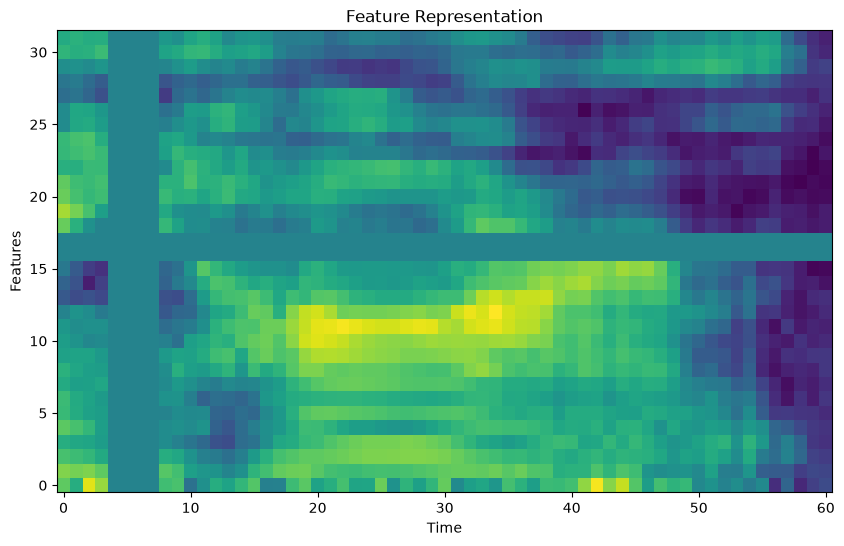

In [23]:
import matplotlib.pyplot as plt

# Testing code to check if your data loaders are working
for i, data in enumerate(train_loader):
    frames, phoneme = data
    print(frames.shape, phoneme.shape)

    # Visualize sample mfcc to inspect and verify everything is correctly done, especially augmentations
    plt.figure(figsize=(10, 6))
    plt.imshow(frames[0].T, aspect='auto', origin='lower', cmap='viridis')
    plt.xlabel('Time')
    plt.ylabel('Features')
    plt.title('Feature Representation')
    plt.show()

    break

In [24]:
# Testing code to check if your validation data loaders are working
all = []
for i, data in enumerate(val_loader):
    frames, phoneme = data
    all.append(phoneme)
    break

# Network Architecture


This section defines your network architecture for the homework. We have given you a sample architecture that can easily clear the very low cutoff for the early submission deadline.

In [25]:
# This architecture will make you cross the very low cutoff
# However, you need to run a lot of experiments to cross the medium or high cutoff

class Network(nn.Module):
    def __init__(self, input_size, output_size):
        super(Network, self).__init__()

        self.model = nn.Sequential(
            torch.nn.Linear(input_size, 2048),
            torch.nn.ReLU(),

            torch.nn.Linear(2048, 2048),
            torch.nn.ReLU(),

            torch.nn.Linear(2048, 2048),
            torch.nn.ReLU(),

            torch.nn.Linear(2048, 512),
            torch.nn.ReLU(),

            torch.nn.Linear(512, output_size)
        )

        if config['weight_initialization'] is not None:
            self.initialize_weights()

    def initialize_weights(self):
        for m in self.modules():
            if isinstance(m, torch.nn.Linear):
                if config["weight_initialization"] == "xavier_normal":
                    torch.nn.init.xavier_normal_(m.weight)
                elif config["weight_initialization"] == "xavier_uniform":
                    torch.nn.init.xavier_uniform_(m.weight)
                elif config["weight_initialization"] == "kaiming_normal":
                    torch.nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                elif config["weight_initialization"] == "kaiming_uniform":
                    torch.nn.init.kaiming_uniform_(m.weight, nonlinearity='relu')
                elif config["weight_initialization"] == "uniform":
                    torch.nn.init.uniform_(m.weight)
                else:
                    raise ValueError("Invalid weight_initialization value")

                # Initialize bias to 0
                m.bias.data.fill_(0)


    def forward(self, x):

        # Flatten to a 1D vector for each data point
        x = torch.flatten(x, start_dim=1)  # Keeps batch size, flattens the rest

        return self.model(x)

# Define Model, Loss Function and Optimizer

Here we define the model, loss function, optimizer and optionally a learning rate scheduler.

In [26]:
INPUT_SIZE = (2 * config["context"] + 1) * 32
model = Network(INPUT_SIZE, len(train_data.phonemes)).to(device)

# HW1 models, including ensembles, must stay below the official 20-million-parameter limit.
trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert trainable_parameters < 20_000_000, "Model exceeds the 20M parameter limit."
print("Trainable parameters:", trainable_parameters)


Trainable parameters: 13462056


In [27]:
# Inspect model architecture & parameter count (purely diagnostic — safe to skip if it errors).
# PSC uses the provided environment; do not install packages into it from the notebook.
ON_PSC = os.path.isdir("/jet/home")
try:
    if not ON_PSC:
        !pip install torchsummaryX==1.1.0 --quiet
    from torchsummaryX import summary
    summary(model, frames.to(device))
except Exception:
    try:
        if not ON_PSC:
            !pip install torchsummary --quiet
        from torchsummary import summary
        summary(model, frames[0].to(device).shape)
    except Exception as e:
        print("Skipping model summary (non-critical):", repr(e))

print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


----------------------------------------------------------------------------------------------------
Layer                   Kernel Shape         Output Shape         # Params (K)      # Mult-Adds (M)
0_Linear                [1952, 2048]         [2048, 2048]             3,999.74                 4.00
1_ReLU                             -         [2048, 2048]                    -                    -
2_Linear                [2048, 2048]         [2048, 2048]             4,196.35                 4.19
3_ReLU                             -         [2048, 2048]                    -                    -
4_Linear                [2048, 2048]         [2048, 2048]             4,196.35                 4.19
5_ReLU                             -         [2048, 2048]                    -                    -
6_Linear                 [2048, 512]          [2048, 512]             1,049.09                 1.05
7_ReLU                             -          [2048, 512]                    -                    -

# Define Model, Loss Function and Optimizer

Here we define the model, loss function, optimizer and optionally a learning rate scheduler.

In [28]:
criterion = torch.nn.CrossEntropyLoss() # Defining Loss function.
# We use CE because the task is multi-class classification

# Choose an appropriate optimizer of your choice
optimizer = torch.optim.AdamW(model.parameters(), lr=config['learning_rate'])

# Recommended : Define Scheduler for Learning Rate,
# including but not limited to StepLR, MultiStep, CosineAnnealing, CosineAnnealingWithWarmRestarts, ReduceLROnPlateau, etc.
# You can refer to Pytorch documentation for more information on how to use them.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2
)

# Is your training time very high?
# Look into mixed precision training if your GPU (Tesla T4, V100, etc) can make use of it
# Refer - https://pytorch.org/docs/stable/notes/amp_examples.html
# Mixed Precision Training with AMP for speedup
scaler = torch.amp.GradScaler('cuda', enabled=True)

# Training and Validation Functions

This section covers the training, and validation functions for each epoch of running your experiment with a given model architecture. The code has been provided to you, but we recommend going through the comments to understand the workflow to enable you to write these loops for future HWs.

In [29]:
# CLEAR RAM!!
torch.cuda.empty_cache()
gc.collect()

318

In [30]:
def train(model, dataloader, optimizer, criterion):

    model.train()
    tloss, tacc = 0, 0 # Monitoring loss and accuracy
    batch_bar   = tqdm(total=len(train_loader), dynamic_ncols=True, leave=False, position=0, desc='Train')

    for i, (frames, phonemes) in enumerate(dataloader):

        ### Initialize Gradients
        optimizer.zero_grad()

        frames      = frames.to(device)
        phonemes    = phonemes.to(device)

        with torch.autocast(device_type=device, dtype=torch.float16):
            ### Forward Propagation
            logits  = model(frames)

            ### Loss Calculation
            loss    = criterion(logits, phonemes)

        ### Backward Propagation
        scaler.scale(loss).backward()

        # OPTIONAL: You can add gradient clipping here, if you face issues of exploding gradients

        ### Gradient Descent
        scaler.step(optimizer)
        scaler.update()

        tloss   += loss.item()
        tacc    += torch.sum(torch.argmax(logits, dim= 1) == phonemes).item()/logits.shape[0]

        batch_bar.set_postfix(loss="{:.04f}".format(float(tloss / (i + 1))),
                              acc="{:.04f}%".format(float(tacc*100 / (i + 1))))
        batch_bar.update()

        ### Release memory
        del frames, phonemes, logits
        torch.cuda.empty_cache()


    batch_bar.close()
    tloss   /= len(train_loader)
    tacc    /= len(train_loader)


    return tloss, tacc

In [31]:
def eval(model, dataloader):

    model.eval() # set model in evaluation mode
    vloss, vacc = 0, 0 # Monitoring loss and accuracy
    batch_bar   = tqdm(total=len(val_loader), dynamic_ncols=True, position=0, leave=False, desc='Val')

    for i, (frames, phonemes) in enumerate(dataloader):

        ### Move data to device (ideally GPU)
        frames      = frames.to(device)
        phonemes    = phonemes.to(device)

        # makes sure that there are no gradients computed as we are not training the model now
        with torch.inference_mode():
            ### Forward Propagation
            logits  = model(frames)
            ### Loss Calculation
            loss    = criterion(logits, phonemes)

        vloss   += loss.item()
        vacc    += torch.sum(torch.argmax(logits, dim= 1) == phonemes).item()/logits.shape[0]

        # Do you think we need loss.backward() and optimizer.step() here?

        batch_bar.set_postfix(loss="{:.04f}".format(float(vloss / (i + 1))),
                              acc="{:.04f}%".format(float(vacc*100 / (i + 1))))
        batch_bar.update()

        ### Release memory
        del frames, phonemes, logits
        torch.cuda.empty_cache()

    batch_bar.close()
    vloss   /= len(val_loader)
    vacc    /= len(val_loader)

    return vloss, vacc

# Weights and Biases Setup

This section is to enable logging metrics and files with Weights and Biases. Please refer to wandb documentationa and recitation 0 that covers the use of weights and biases for logging, hyperparameter tuning and monitoring your runs for your homeworks. Using this tool makes it very easy to show results when submitting your code and models for homeworks, and also extremely useful for study groups to organize and run ablations under a single team in wandb.

We have written code for you to make use of it out of the box, so that you start using wandb for all your HWs from the beginning.

In [34]:
# W&B is used for experiment logging and the final Gradescope code submission.
# Keep API keys out of notebook source by using an environment variable or hidden prompt.
import getpass
import os

WANDB_API_KEY = os.environ.get("WANDB_API_KEY", "").strip()
if not WANDB_API_KEY:
    WANDB_API_KEY = getpass.getpass("Weights & Biases API key: ").strip()

WANDB_USERNAME_OR_TEAMNAME = input(
    "W&B username/team entity (leave blank to use your default entity): "
).strip()
WANDB_PROJECT = "hw1p2"

wandb.login(key=WANDB_API_KEY)
if not WANDB_USERNAME_OR_TEAMNAME:
    WANDB_USERNAME_OR_TEAMNAME = wandb.Api().default_entity
print(f"W&B runs -> {WANDB_USERNAME_OR_TEAMNAME}/{WANDB_PROJECT}")


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\jrzem\_netrc


W&B runs -> jzembowe-carnegie-mellon-university/hw1p2


In [35]:
# Create or resume a W&B run.
RESUME_OLD_RUN = False
WANDB_RUN_ID = ""  # TODO: Fill only when resuming a specific run.

if RESUME_OLD_RUN:
    run = wandb.init(
        name=config["Name"],
        id=WANDB_RUN_ID,
        resume="must",
        entity=WANDB_USERNAME_OR_TEAMNAME,
        project=WANDB_PROJECT,
        config=config,
    )
else:
    run = wandb.init(
        name=config["Name"],
        entity=WANDB_USERNAME_OR_TEAMNAME,
        project=WANDB_PROJECT,
        config=config,
        reinit=True,
    )


In [36]:
### Save your model architecture as a string with str(model)
model_arch  = str(model)

### Save it in a txt file
arch_file   = open("model_arch.txt", "w")
file_write  = arch_file.write(model_arch)
arch_file.close()

### log it in your wandb run with wandb.save()
wandb.save('model_arch.txt')

wandb: WARNING Linked 1 file into the W&B run directory (hardlinks); call wandb.save again to sync new files.


['c:\\code_projects\\IDL_HW1P2\\wandb\\run-20260904_224139-p08gg1bq\\files\\model_arch.txt']

### Define functions to save model and load checkpoint

In [37]:
def save_model(model, optimizer, scheduler, metric, epoch, path):
    torch.save({
        'model_state_dict'         : model.state_dict(),
        'optimizer_state_dict'     : optimizer.state_dict(),
        'scheduler_state_dict'     : scheduler.state_dict(),
        metric[0]                  : metric[1],
        'epoch'                    : epoch
    }, path)

    # Upload the same checkpoint to WandB
    wandb.save(path, base_path=os.path.dirname(path))

In [38]:
def load_checkpoint(checkpoint_path, model, optimizer, scheduler):

    # load the checkpoint model
    checkpoint = torch.load(checkpoint_path)

    # Check if module is an instance of DataParallel or normal model and load the state dict appropriately
    if isinstance(model, torch.nn.DataParallel):
        print("Model is an instance of Data Parallel")
        model.module.load_state_dict(checkpoint['model_state_dict'])
    else:
        print("Model is a normal model instance")
        model.load_state_dict(checkpoint['model_state_dict'])

    # Load state dicts of the optimizer and scheduler
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

    # retrieve val accuracy and epoch
    valid_acc = checkpoint['valid_acc']
    epoch = checkpoint['epoch']

    # return val accuracy and epoch
    return valid_acc, epoch

# Experiment

Now, it is time to finally run your ablations! Have fun!

In [39]:
# Iterate over number of epochs to train and evaluate your model
torch.cuda.empty_cache()
gc.collect()
wandb.watch(model, log="all")

for epoch in range(config['epochs']):

    print("\nEpoch {}/{}".format(epoch+1, config['epochs']))

    curr_lr                 = float(optimizer.param_groups[0]['lr'])
    train_loss, train_acc   = train(model, train_loader, optimizer, criterion)
    val_loss, val_acc       = eval(model, val_loader)

    print("\tTrain Acc {:.04f}%\tTrain Loss {:.04f}\t Learning Rate {:.07f}".format(train_acc*100, train_loss, curr_lr))
    print("\tVal Acc {:.04f}%\tVal Loss {:.04f}".format(val_acc*100, val_loss))

    ## Log metrics at each epoch in your run
    # Optionally, you can log at each batch inside train/eval functions
    # (explore wandb documentation/wandb recitation)
    wandb.log({'train_acc': train_acc*100, 'train_loss': train_loss,
               'val_acc': val_acc*100, 'valid_loss': val_loss, 'lr': curr_lr})

    # If using a scheduler, step the learning rate here, otherwise comment this line
    # Depending on the scheduler in use, you may or may not need to pass in a metric into the step function, so read the docs well
    scheduler.step(val_acc)

    ## HIGHLY RECOMMENDED: Save model checkpoint in drive and/or wandb if accuracy is better than your current best accuracy
    ## This enables you to resume training at anytime, without having to start from scratch.
    ## Refer to Recitation 0.24 to learn how to implement this: https://www.youtube.com/watch?v=-TCH0DbUEKM&list=PLp-0K3kfddPw2D5CeA09lsx_oNy9E


Epoch 1/5


	Train Acc 70.3940%	Train Loss 0.9378	 Learning Rate 0.0010000
	Val Acc 76.3234%	Val Loss 0.7410

Epoch 2/5


	Train Acc 76.1370%	Train Loss 0.7477	 Learning Rate 0.0010000
	Val Acc 78.2296%	Val Loss 0.6820

Epoch 3/5


	Train Acc 77.6828%	Train Loss 0.6972	 Learning Rate 0.0010000
	Val Acc 79.1910%	Val Loss 0.6518

Epoch 4/5


	Train Acc 78.5770%	Train Loss 0.6684	 Learning Rate 0.0010000
	Val Acc 79.7192%	Val Loss 0.6340

Epoch 5/5


	Train Acc 79.3114%	Train Loss 0.6443	 Learning Rate 0.0010000
	Val Acc 80.3560%	Val Loss 0.6163


# Testing and submission to Kaggle

Before we get to the following code, make sure to see the format of submission given in *sample_submission.csv*. Once you have done so, it is time to fill the following function to complete your inference on test data. Refer the eval function from previous cells to get an idea of how to go about completing this function.

In [40]:
def test(model, test_loader):
    model.eval()

    ### List to store predicted phonemes of test data
    test_predictions = []

    with torch.inference_mode():

        for i, mfccs in enumerate(tqdm(test_loader)):

            mfccs   = mfccs.to(device)

            logits  = model(mfccs)

            ### Get most likely predicted phoneme with argmax
            predicted_phonemes = torch.argmax(logits, dim=1)

            ### Map integer indices back to phoneme strings
            test_predictions.extend(PHONEMES[j] for j in predicted_phonemes.cpu().tolist())

    ## SANITY CHECK
    sample_predictions = test_predictions[:10]
    if not isinstance(sample_predictions[0], str):
        print(f"❌ ERROR: Predictions should be phoneme STRINGS, not {type(sample_predictions[0]).__name__}!")
        print(f"   You need to convert integer indices to their corresponding phoneme strings")
        print(f"   Hint: Look at the eval() function to get the idea")

    # Print a preview of predictions for manual inspection
    print("\nSample predictions:", sample_predictions)
    print("\nPredictions Generated successfully!")

    return test_predictions


In [41]:
# Generate model test predictions

predictions = test(model, test_loader)

100%|██████████| 862/862 [00:15<00:00, 57.40it/s]


Sample predictions: ['[SIL]', '[SIL]', '[SIL]', '[SIL]', '[SIL]', '[SIL]', '[SIL]', '[SIL]', '[SIL]', '[SIL]']

Predictions Generated successfully!


In [42]:
### Create CSV file with predictions
# sample_submission.csv uses header `ID,TARGET` with 1-indexed IDs

with open("./submission.csv", "w+") as f:
    f.write("ID,TARGET\n")
    for i in range(len(predictions)):
        f.write("{},{}\n".format(i + 1, predictions[i]))

    print("submission.csv file created successfully!")

submission.csv file created successfully!


In [44]:
### Finish your wandb run
run.finish()

lr,▁▁▁▁▁
train_acc,▁▆▇▇█
train_loss,█▃▂▂▁
val_acc,▁▄▆▇█
valid_loss,█▅▃▂▁
lr,0.001
train_acc,79.31139
train_loss,0.64434
val_acc,80.356
valid_loss,0.61628


# Submit to kaggle competition using kaggle API

In [43]:
# Set this to True only when you intentionally want to submit to Kaggle.
SUBMIT_TO_KAGGLE = True
USE_SLACK_COMPETITION = False

if SUBMIT_TO_KAGGLE:
    target_competition = SLACK_COMPETITION if USE_SLACK_COMPETITION else COMPETITION
    if target_competition.startswith("<"):
        raise RuntimeError("The selected F26 Kaggle competition slug has not been inserted yet.")
    api.competition_submit(
        file_name="submission.csv",
        message="HW1P2 submission",
        competition=target_competition,
    )
    print(f"Submitted submission.csv to {target_competition}")
else:
    print("Kaggle submission skipped. Set SUBMIT_TO_KAGGLE = True to submit intentionally.")


100%|██████████| 19.3M/19.3M [00:12<00:00, 1.63MB/s]


Submitted submission.csv to hw-1-p-2-fall-2026-student-competition


## 📦 Gradescope Submission Instructions (Read Carefully)

This section guides you through creating and submitting your **final Gradescope code submission**.
Please follow each step in order. Skipping steps may result in an incomplete or invalid submission.

### ⏰ Important Deadlines

* **Kaggle Final Deadline:** See the course schedule
* **Gradescope Code Submission Deadline:**
  **48 hours after** the Kaggle deadline (or the same day as your Slack Kaggle submission, if applicable)

You must submit **both**:

1. A valid Kaggle submission
2. A complete Gradescope code submission zip

Please assign your **final trained model** to the global variable `MODEL`.

We will use this variable to automatically generate a file named
`model_metadata.json`, which records important information about your model (such as parameter count and architecture).

#### 🔴 Important Requirements

* **`MODEL` must be the exact model used for your best Kaggle submission**
* This step is **required** for grading and audit purposes
* If the model does not match your Kaggle submission, your score may be invalidated

#### 🕒 When to Do This

* Run this cell **only after you have finished training** your final model
* Do **not** retrain or modify the model after assigning it to `MODEL`

In [ ]:
MODEL = model  # your final trained model (this notebook trains into `model`)

### Step 2: Complete the README Section

Fill in the `README` variable with a brief description of your work:

* **Model**: Architecture and key design choices
* **Training Strategy**: Optimizer, scheduler, loss, etc.
* **Augmentations**: If used (omit if not)
* **Notebook Execution**: Any instructions needed to run your notebook

This README will be included in your submission zip.

In [ ]:
README = """
- **Model**: Model archtiecture description. Anything unique? Any specific architecture shapes or strategies?
- **Training Strategy**: optimizer + scheduler + loss function + any other unique ideas
- **Augmentations**: augmentations if used. If augmentations weren't used, then ignore
- **Notebook Execution**: Any instructions required to run your notebook.
"""

### Step 3: Provide Required Credentials

Ensure the following variables are correctly set:

* `KAGGLE_USERNAME`
* `KAGGLE_API_KEY`
* `WANDB_API_KEY`
* `WANDB_USERNAME_OR_TEAMNAME`
* `WANDB_PROJECT`

These are used **only** to:

* Fetch your official Kaggle score
* Export your top WandB runs for grading

⚠️ Do **not** share your API keys publicly.

In [ ]:
KAGGLE_USERNAME = "<your-kaggle-username>"                              # TODO: verify in Kaggle Settings
KAGGLE_API_KEY  = KAGGLE_API_TOKEN                           # reuse the KGAT token from the Kaggle auth cell
WANDB_API_KEY   = "<your-wandb-api-key>" # TODO: your W&B API key
WANDB_USERNAME_OR_TEAMNAME = ""                              # TODO: your W&B username or team (entity)
WANDB_PROJECT              = "hw1p2"                         # the W&B project your runs are under

### Step 4: Set File Paths Correctly

You must provide absolute path to your **final notebook**

### Platform-specific guidance

**Colab**

* Right-click a file in the left file pane → **Copy path**
* Paths typically start with `/content/...`

**Kaggle**

* Download your notebook (`File → Download Notebook`)
* Upload it via **Upload Input → Upload Model**
* Copy paths from the right sidebar (`/kaggle/working/...`)

**PSC / Linux**

* Locate files under `/jet/home/<your_username>/`
* Use `!ls` to confirm paths

Paste the correct path below.

In [ ]:
NOTEBOOK_PATH = ""  # TODO: Paste the absolute path to your completed F26 student notebook.


### Step 5: (Optional) Additional Files

If you have extra files you want to include (e.g., config files, scripts), add their paths to `ADDITIONAL_FILES`, Otherwise, leave this list empty.

In [ ]:
ADDITIONAL_FILES = []

### Step 6: Generate the Final Submission Zip

Before running the submission cell:

* Ensure `ACKNOWLEDGED = True`
* Double-check all paths and credentials
* Confirm your Kaggle submission exists

Then run the cell below.
This should generate a `HW1P2_final_submission.zip` which includes:
* Your notebook
* `model_metadata_*.json`
* README
* WandB run exports
* Kaggle metadata
* Academic integrity acknowledgement

In [ ]:
#### DO NOT MODIFY ####
from submission.submission_config import SubmissionConfig
from submission.backend_config import BackendConfig, HW1P2_BACKEND_CONFIG # HW1P2 backend config
from submission.main import create_submission_zip

create_submission_zip(
    cfg = SubmissionConfig(
        model = MODEL,
        kaggle_username  = KAGGLE_USERNAME,
        kaggle_api_key   = KAGGLE_API_KEY,
        wandb_api_key    = WANDB_API_KEY,
        wandb_entity     = WANDB_USERNAME_OR_TEAMNAME,
        wandb_project    = WANDB_PROJECT,
        acknowledged     = ACKNOWLEDGED,
        readme           = README,
        notebook_path    = NOTEBOOK_PATH,
        additional_files = ADDITIONAL_FILES
    ),
    backend_cfg = HW1P2_BACKEND_CONFIG
)

### Step 7: Upload to Gradescope

1. Download `HW1P2_final_submission.zip`
2. Upload it to **Gradescope**
3. Verify the upload succeeds

⚠️ Submitting an incomplete zip or modifying backend code may result in grading penalties or an Academic Integrity Violation.

---

### ✅ Final Checklist

Before submitting, confirm:

* [ ] Kaggle username is valid
* [ ] `model_metadata_*.json` matches your best run
* [ ] README is complete
* [ ] File paths are correct
* [ ] `ACKNOWLEDGED = True`
* [ ] Final zip downloads successfully